In [1]:
%pip install -q torch pandas numpy opencv-python

Note: you may need to restart the kernel to use updated packages.


### Import packages

In [1]:
import base64
import json
import pandas as pd
import numpy as np
import torch
import cv2

In [2]:
# Optional pandas display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 10)

In [3]:
print("PyTorch version :", torch.__version__)
print("Pandas version  :", pd.__version__)
print("NumPy version   :", np.__version__)
print("OpenCV version  :", cv2.__version__)

PyTorch version : 2.13.0+cpu
Pandas version  : 2.3.3
NumPy version   : 2.4.6
OpenCV version  : 5.0.0


### Before and after RAM Spike

In [4]:
# Optional: install once
# %pip install -q psutil
import os
import time
import psutil

process = psutil.Process(os.getpid())
ram_before = process.memory_info().rss / (1024 ** 3)
print(f"RAM used before loading: {ram_before:.2f} GB")

RAM used before loading: 0.27 GB


In [5]:
# Baseline: Unoptimized CSV loading
CSV_PATH = "../nexlyra_strain_ml_1M_ravi.csv"
start_time = time.time()
df = pd.read_csv(CSV_PATH)
elapsed_time = time.time() - start_time
ram_after = process.memory_info().rss / (1024 ** 3)

print(f"Loading time: {elapsed_time:.2f} seconds")
print(f"RAM used after loading: {ram_after:.2f} GB")

print("\nDataFrame shape:")
print(df.shape)

print("\nDataFrame memory usage:")
print(f"{df.memory_usage(deep=True).sum() / (1024 ** 3):.2f} GB")

Loading time: 12.68 seconds
RAM used after loading: 1.10 GB

DataFrame shape:
(1000000, 9)

DataFrame memory usage:
0.96 GB


In [6]:
df.columns

Index(['Log_ID', 'Timestamp', 'Column_ID', 'Vendor', 'Operational_State',
       'Axial_Load_Tons', 'Wind_Shear_MPH', 'Strain_Matrix_B64',
       'MicroFracture_Triggered'],
      dtype='object')

In [7]:
# CSV configuration
CSV_PATH = "../nexlyra_strain_ml_1M_ravi.csv"
CHUNK_SIZE = 50000
STRAIN_COLUMN = "Strain_Matrix_B64"
EXPECTED_LENGTH = 64

In [8]:
print("CSV path:", CSV_PATH)
print("Chunk size:", CHUNK_SIZE)
print("Expected tensor length:", EXPECTED_LENGTH)

CSV path: ../nexlyra_strain_ml_1M_ravi.csv
Chunk size: 50000
Expected tensor length: 64


In [9]:
# Safe JSON parsing
def safe_json_loads(value):

    try:
        return json.loads(value)

    except (json.JSONDecodeError, TypeError, ValueError):
        return None

In [10]:
# Base64 decoder
def decode_base64_to_array(value):
    # Handle missing values
    if pd.isna(value):
        return None

    try:
        # Base64 → bytes
        decoded_bytes = base64.b64decode(value,validate=True)

        # bytes → JSON string
        json_string = decoded_bytes.decode("utf-8")

    except (ValueError, TypeError, UnicodeDecodeError):
        return None

    # JSON string → Python list

    parsed_list = safe_json_loads(json_string)

    if not isinstance(parsed_list, list):
        return None
    # Python list → NumPy array
    try:
        array = np.asarray(parsed_list,dtype=np.float32)
    except (ValueError, TypeError):
        return None

    # Ensure 1D
    if array.ndim != 1:
        return None

    return array

In [11]:
# Chunked CSV processing
total_rows = 0
valid_rows = 0
invalid_rows = 0
jagged_rows = []
processed_chunks = []

for chunk_number, chunk in enumerate(pd.read_csv(CSV_PATH,chunksize=CHUNK_SIZE),start=1):
    print("\n" + "=" * 70)
    print(f"Processing chunk {chunk_number}")
    print("=" * 70)

    # Track original CSV row numbers
    chunk_start = total_rows
    total_rows += len(chunk)
    print(f"Rows in chunk: {len(chunk):,}")

    # Isolate Base64 column
    strain_b64 = chunk[STRAIN_COLUMN]
    # Decode Base64 → JSON → NumPy
    decoded_arrays = strain_b64.apply(lambda x: decode_base64_to_array(x))

    # Determine tensor length
    lengths = decoded_arrays.apply(lambda x: (len(x) if isinstance(x, np.ndarray) else -1))
    # Identify jagged tensors
    jagged_mask = (lengths != EXPECTED_LENGTH)

    number_of_jagged = int(jagged_mask.sum())

    # Store original row numbers
    if number_of_jagged > 0:

        local_indices = np.where(jagged_mask.to_numpy())[0]
        original_indices = (chunk_start + local_indices)
        jagged_rows.extend(original_indices.tolist())

    # Identify valid tensors
    valid_mask = (lengths == EXPECTED_LENGTH)
    number_of_valid = int(valid_mask.sum())
    number_of_invalid = (len(chunk) - number_of_valid)

    valid_rows += number_of_valid
    invalid_rows += number_of_invalid

    # Add decoded arrays to chunk
    chunk["Strain_Array"] = decoded_arrays

    # Remove massive Base64 column
    chunk = chunk.drop(columns=[STRAIN_COLUMN])

    # Store processed chunk
    processed_chunks.append(chunk)
    # Progress information

    print(f"Valid tensors   : {number_of_valid:,}")

    print(f"Invalid tensors : {number_of_invalid:,}")

    print(f"Jagged tensors  : {number_of_jagged:,}")


Processing chunk 1
Rows in chunk: 50,000
Valid tensors   : 49,520
Invalid tensors : 480
Jagged tensors  : 480

Processing chunk 2
Rows in chunk: 50,000
Valid tensors   : 49,515
Invalid tensors : 485
Jagged tensors  : 485

Processing chunk 3
Rows in chunk: 50,000
Valid tensors   : 49,500
Invalid tensors : 500
Jagged tensors  : 500

Processing chunk 4
Rows in chunk: 50,000
Valid tensors   : 49,418
Invalid tensors : 582
Jagged tensors  : 582

Processing chunk 5
Rows in chunk: 50,000
Valid tensors   : 49,476
Invalid tensors : 524
Jagged tensors  : 524

Processing chunk 6
Rows in chunk: 50,000
Valid tensors   : 49,536
Invalid tensors : 464
Jagged tensors  : 464

Processing chunk 7
Rows in chunk: 50,000
Valid tensors   : 49,495
Invalid tensors : 505
Jagged tensors  : 505

Processing chunk 8
Rows in chunk: 50,000
Valid tensors   : 49,486
Invalid tensors : 514
Jagged tensors  : 514

Processing chunk 9
Rows in chunk: 50,000
Valid tensors   : 49,505
Invalid tensors : 495
Jagged tensors  : 495



In [12]:
# Find specifically 63-element tensors
jagged_63_rows = []

for chunk_number, chunk in enumerate(processed_chunks):
    arrays = chunk["Strain_Array"]

    for local_index, array in arrays.items():
        if (isinstance(array, np.ndarray) and len(array) == 63):
            jagged_63_rows.append(local_index)

print(
    f"63-element tensors found: "
    f"{len(jagged_63_rows):,}")

63-element tensors found: 10,030


- However, there is an important issue with the above approach: after chunking, the local_index is not necessarily the original CSV row number. A cleaner approach is to record the original index during the chunk-processing loop:

In [13]:
# Recommended jagged tensor tracking
jagged_63_rows = []
total_rows = 0

for chunk_number, chunk in enumerate(
    pd.read_csv(CSV_PATH,chunksize=CHUNK_SIZE),start=1):

    chunk_start = total_rows
    total_rows += len(chunk)
    decoded_arrays = chunk[STRAIN_COLUMN].apply(lambda x: decode_base64_to_array(x))
    lengths = decoded_arrays.apply(lambda x: (len(x)if isinstance(x, np.ndarray)else -1))

    # Specifically 63 elements
    mask_63 = (lengths == 63)
    local_indices = np.where(mask_63.to_numpy())[0]
    original_indices = (chunk_start + local_indices)
    jagged_63_rows.extend(original_indices.tolist())

    print(f"Chunk {chunk_number}: "
          f"{len(original_indices)} "
          f"63-element tensors")


print("\nTotal 63-element tensors:")
print(len(jagged_63_rows))

print("\nSample row indices:")
print(jagged_63_rows[:20])

Chunk 1: 480 63-element tensors
Chunk 2: 485 63-element tensors
Chunk 3: 500 63-element tensors
Chunk 4: 582 63-element tensors
Chunk 5: 524 63-element tensors
Chunk 6: 464 63-element tensors
Chunk 7: 505 63-element tensors
Chunk 8: 514 63-element tensors
Chunk 9: 495 63-element tensors
Chunk 10: 558 63-element tensors
Chunk 11: 535 63-element tensors
Chunk 12: 476 63-element tensors
Chunk 13: 447 63-element tensors
Chunk 14: 523 63-element tensors
Chunk 15: 558 63-element tensors
Chunk 16: 466 63-element tensors
Chunk 17: 492 63-element tensors
Chunk 18: 482 63-element tensors
Chunk 19: 463 63-element tensors
Chunk 20: 481 63-element tensors

Total 63-element tensors:
10030

Sample row indices:
[43, 381, 532, 633, 768, 861, 912, 1009, 1081, 1087, 1116, 1298, 1299, 1442, 1529, 1548, 1666, 1750, 1815, 1821]


In [14]:
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

In [15]:
TARGET_LENGTH = 64


def normalize_strain_array(array, target_length=TARGET_LENGTH):
    """
    Normalize a 1D strain array to exactly target_length elements.
    - Missing/invalid arrays -> None
    - Short arrays -> interpolation
    - Long arrays -> interpolation/resampling
    - Already 64 -> unchanged
    """

    # Handle invalid input
    if not isinstance(array, np.ndarray):
        return None

    if array.ndim != 1:
        return None

    if len(array) == 0:
        return None

    # Convert to float32
    array = np.asarray(array, dtype=np.float32)

    # Already correct length
    if len(array) == target_length:
        return array

    # Original positions
    old_positions = np.linspace(0,1,num=len(array))

    # New positions
    new_positions = np.linspace(0,1, num=target_length)

    # Linear interpolation
    normalized_array = np.interp(new_positions,old_positions,array)

    return normalized_array.astype(np.float32)

In [16]:
for chunk_number, chunk in enumerate(processed_chunks, start=1):

    chunk["Strain_Array"] = chunk["Strain_Array"].apply(normalize_strain_array)

    print(f"Chunk {chunk_number}: "f"Strain arrays normalized to {TARGET_LENGTH} elements")

Chunk 1: Strain arrays normalized to 64 elements
Chunk 2: Strain arrays normalized to 64 elements
Chunk 3: Strain arrays normalized to 64 elements
Chunk 4: Strain arrays normalized to 64 elements
Chunk 5: Strain arrays normalized to 64 elements
Chunk 6: Strain arrays normalized to 64 elements
Chunk 7: Strain arrays normalized to 64 elements
Chunk 8: Strain arrays normalized to 64 elements
Chunk 9: Strain arrays normalized to 64 elements
Chunk 10: Strain arrays normalized to 64 elements
Chunk 11: Strain arrays normalized to 64 elements
Chunk 12: Strain arrays normalized to 64 elements
Chunk 13: Strain arrays normalized to 64 elements
Chunk 14: Strain arrays normalized to 64 elements
Chunk 15: Strain arrays normalized to 64 elements
Chunk 16: Strain arrays normalized to 64 elements
Chunk 17: Strain arrays normalized to 64 elements
Chunk 18: Strain arrays normalized to 64 elements
Chunk 19: Strain arrays normalized to 64 elements
Chunk 20: Strain arrays normalized to 64 elements


In [17]:
def reshape_to_8x8(array):

    if not isinstance(array, np.ndarray):
        return None

    if array.shape != (64,):
        return None

    return array.reshape(8, 8)

In [18]:
for chunk_number, chunk in enumerate(processed_chunks, start=1):

    chunk["Strain_Matrix"] = chunk["Strain_Array"].apply(reshape_to_8x8)

    print(f"Chunk {chunk_number}: "
          f"64 → 8x8 completed")

Chunk 1: 64 → 8x8 completed
Chunk 2: 64 → 8x8 completed
Chunk 3: 64 → 8x8 completed
Chunk 4: 64 → 8x8 completed
Chunk 5: 64 → 8x8 completed
Chunk 6: 64 → 8x8 completed
Chunk 7: 64 → 8x8 completed
Chunk 8: 64 → 8x8 completed
Chunk 9: 64 → 8x8 completed
Chunk 10: 64 → 8x8 completed
Chunk 11: 64 → 8x8 completed
Chunk 12: 64 → 8x8 completed
Chunk 13: 64 → 8x8 completed
Chunk 14: 64 → 8x8 completed
Chunk 15: 64 → 8x8 completed
Chunk 16: 64 → 8x8 completed
Chunk 17: 64 → 8x8 completed
Chunk 18: 64 → 8x8 completed
Chunk 19: 64 → 8x8 completed
Chunk 20: 64 → 8x8 completed


In [19]:
sample_matrix = processed_chunks[0]["Strain_Matrix"].iloc[0]
print(sample_matrix)
print("Shape:", sample_matrix.shape)
print("Dtype:", sample_matrix.dtype)

[[0.963 1.281 1.101 1.236 1.076 1.15  1.114 1.187]
 [1.021 1.071 1.196 1.091 1.195 1.366 1.402 1.341]
 [0.929 0.864 1.144 1.145 1.153 1.264 1.405 1.442]
 [0.868 1.087 1.214 1.155 1.192 1.257 1.445 1.424]
 [0.753 1.098 1.123 1.039 1.354 1.304 1.373 1.313]
 [1.045 1.027 1.009 1.288 1.317 1.448 1.342 1.449]
 [1.072 0.988 1.227 1.2   1.103 1.074 1.387 1.249]
 [1.138 0.982 1.18  1.183 1.127 1.339 1.254 1.383]]
Shape: (8, 8)
Dtype: float32


In [20]:
def matrix_to_tensor(matrix):

    if not isinstance(matrix, np.ndarray):
        return None

    if matrix.shape != (8, 8):
        return None

    return torch.from_numpy(matrix.astype(np.float32)).unsqueeze(0)

In [21]:
for chunk_number, chunk in enumerate(processed_chunks, start=1):

    chunk["Strain_Tensor"] = chunk["Strain_Matrix"].apply(matrix_to_tensor)

    print(f"Chunk {chunk_number}: "
          f"8x8 → [1, 8, 8] completed")

Chunk 1: 8x8 → [1, 8, 8] completed
Chunk 2: 8x8 → [1, 8, 8] completed
Chunk 3: 8x8 → [1, 8, 8] completed
Chunk 4: 8x8 → [1, 8, 8] completed
Chunk 5: 8x8 → [1, 8, 8] completed
Chunk 6: 8x8 → [1, 8, 8] completed
Chunk 7: 8x8 → [1, 8, 8] completed
Chunk 8: 8x8 → [1, 8, 8] completed
Chunk 9: 8x8 → [1, 8, 8] completed
Chunk 10: 8x8 → [1, 8, 8] completed
Chunk 11: 8x8 → [1, 8, 8] completed
Chunk 12: 8x8 → [1, 8, 8] completed
Chunk 13: 8x8 → [1, 8, 8] completed
Chunk 14: 8x8 → [1, 8, 8] completed
Chunk 15: 8x8 → [1, 8, 8] completed
Chunk 16: 8x8 → [1, 8, 8] completed
Chunk 17: 8x8 → [1, 8, 8] completed
Chunk 18: 8x8 → [1, 8, 8] completed
Chunk 19: 8x8 → [1, 8, 8] completed
Chunk 20: 8x8 → [1, 8, 8] completed


In [22]:
sample_tensor = processed_chunks[0]["Strain_Tensor"].iloc[0]

print("Tensor:")
print(sample_tensor)

print("Shape:", sample_tensor.shape)
print("Dtype:", sample_tensor.dtype)

Tensor:
tensor([[[0.9630, 1.2810, 1.1010, 1.2360, 1.0760, 1.1500, 1.1140, 1.1870],
         [1.0210, 1.0710, 1.1960, 1.0910, 1.1950, 1.3660, 1.4020, 1.3410],
         [0.9290, 0.8640, 1.1440, 1.1450, 1.1530, 1.2640, 1.4050, 1.4420],
         [0.8680, 1.0870, 1.2140, 1.1550, 1.1920, 1.2570, 1.4450, 1.4240],
         [0.7530, 1.0980, 1.1230, 1.0390, 1.3540, 1.3040, 1.3730, 1.3130],
         [1.0450, 1.0270, 1.0090, 1.2880, 1.3170, 1.4480, 1.3420, 1.4490],
         [1.0720, 0.9880, 1.2270, 1.2000, 1.1030, 1.0740, 1.3870, 1.2490],
         [1.1380, 0.9820, 1.1800, 1.1830, 1.1270, 1.3390, 1.2540, 1.3830]]])
Shape: torch.Size([1, 8, 8])
Dtype: torch.float32


### Impute Wind_Shear_MPH using rolling median

In [23]:
WIND_COLUMN = "Wind_Shear_MPH"
total_wind_nan = 0

for chunk_number, chunk in enumerate(processed_chunks, start=1):

    nan_count = chunk[WIND_COLUMN].isna().sum()

    total_wind_nan += nan_count

    print(f"Chunk {chunk_number}: "
          f"{nan_count:,} NaN values")

print(f"\nTotal NaN values in {WIND_COLUMN}: "
      f"{total_wind_nan:,}")

Chunk 1: 0 NaN values
Chunk 2: 0 NaN values
Chunk 3: 0 NaN values
Chunk 4: 0 NaN values
Chunk 5: 0 NaN values
Chunk 6: 0 NaN values
Chunk 7: 0 NaN values
Chunk 8: 0 NaN values
Chunk 9: 0 NaN values
Chunk 10: 0 NaN values
Chunk 11: 0 NaN values
Chunk 12: 0 NaN values
Chunk 13: 0 NaN values
Chunk 14: 0 NaN values
Chunk 15: 0 NaN values
Chunk 16: 0 NaN values
Chunk 17: 0 NaN values
Chunk 18: 0 NaN values
Chunk 19: 0 NaN values
Chunk 20: 0 NaN values

Total NaN values in Wind_Shear_MPH: 0


In [24]:
total_rows_processed = sum(len(chunk) for chunk in processed_chunks)

print(f"Missing Wind_Shear_MPH: "
     f"{total_wind_nan:,} "
     f"({total_wind_nan / total_rows_processed * 100:.4f}%)")

Missing Wind_Shear_MPH: 0 (0.0000%)


- Since Timestamp is available, first convert it to datetime and sort chronologically.

In [25]:
for chunk in processed_chunks:
    chunk["Timestamp"] = pd.to_datetime(chunk["Timestamp"],errors="coerce")
    chunk.sort_values("Timestamp",inplace=True)

In [26]:
ROLLING_WINDOW = 5
for chunk_number, chunk in enumerate(processed_chunks, start=1):
    missing_before = chunk[WIND_COLUMN].isna().sum()
    rolling_median = (chunk[WIND_COLUMN].rolling(window=ROLLING_WINDOW,min_periods=1,center=True).median())
    chunk[WIND_COLUMN] = (chunk[WIND_COLUMN].fillna(rolling_median))
    missing_after = chunk[WIND_COLUMN].isna().sum()

    print(
        f"Chunk {chunk_number}: "
        f"Before={missing_before:,}, "
        f"After={missing_after:,}"
    )

Chunk 1: Before=0, After=0
Chunk 2: Before=0, After=0
Chunk 3: Before=0, After=0
Chunk 4: Before=0, After=0
Chunk 5: Before=0, After=0
Chunk 6: Before=0, After=0
Chunk 7: Before=0, After=0
Chunk 8: Before=0, After=0
Chunk 9: Before=0, After=0
Chunk 10: Before=0, After=0
Chunk 11: Before=0, After=0
Chunk 12: Before=0, After=0
Chunk 13: Before=0, After=0
Chunk 14: Before=0, After=0
Chunk 15: Before=0, After=0
Chunk 16: Before=0, After=0
Chunk 17: Before=0, After=0
Chunk 18: Before=0, After=0
Chunk 19: Before=0, After=0
Chunk 20: Before=0, After=0


### Check MicroFracture_Triggered class imbalance

In [27]:
TARGET_COLUMN = "MicroFracture_Triggered"
target_counts = {}

for chunk in processed_chunks:
    counts = chunk[TARGET_COLUMN].value_counts(dropna=False)

    for label, count in counts.items():
        target_counts[label] = (target_counts.get(label, 0) + int(count))

print("Target distribution:")
print(target_counts)

Target distribution:
{0: 932024, 1: 67976}


In [28]:
print("\nClass percentages:")

total = sum(target_counts.values())

for label, count in sorted(target_counts.items()):
    percentage = count / total * 100

    print(
        f"Class {label}: "
        f"{count:,} "
        f"({percentage:.4f}%)"
    )


Class percentages:
Class 0: 932,024 (93.2024%)
Class 1: 67,976 (6.7976%)


### Exact positive-class ratio

In [29]:
negative_count = target_counts.get(0, 0)
positive_count = target_counts.get(1, 0)

total_samples = negative_count + positive_count

positive_ratio = positive_count / total_samples

print(f"Negative samples : {negative_count:,}")
print(f"Positive samples : {positive_count:,}")
print(f"Total samples    : {total_samples:,}")

print(
    f"\nPositive class ratio: "
    f"{positive_ratio:.8f}"
)

print(
    f"Positive class percentage: "
    f"{positive_ratio * 100:.4f}%"
)

Negative samples : 932,024
Positive samples : 67,976
Total samples    : 1,000,000

Positive class ratio: 0.06797600
Positive class percentage: 6.7976%


In [30]:
metadata_records = []
global_index = 0

for chunk_number, chunk in enumerate(processed_chunks):

    for local_index, target in enumerate(chunk[TARGET_COLUMN].values):
        metadata_records.append({
            "global_index": global_index,
            "chunk_number": chunk_number,
            "local_index": local_index,
            "target": target})

        global_index += 1

In [31]:
metadata_df = pd.DataFrame(metadata_records)

print(metadata_df.head())
print(f"Metadata rows: {len(metadata_df):,}")

   global_index  chunk_number  local_index  target
0             0             0            0       0
1             1             0            1       0
2             2             0            2       0
3             3             0            3       0
4             4             0            4       0
Metadata rows: 1,000,000


### Stratified 70/15/15 split

In [32]:
indices = np.arange(len(metadata_df))

train_indices, temp_indices = train_test_split(indices,test_size=0.30,
                            stratify=metadata_df[TARGET_COLUMN if TARGET_COLUMN in metadata_df.columns else "target"],random_state=42)

In [33]:
train_indices, temp_indices = train_test_split(indices,
                                         test_size=0.30,
                                         stratify=metadata_df["target"],
                                         random_state=42)

In [34]:
val_indices, test_indices = train_test_split(temp_indices,
                                             test_size=0.50,
                                             stratify=metadata_df.iloc[temp_indices]["target"],
                                            random_state=42)

### splite Varification

In [35]:
print(f"Train      : {len(train_indices):,} "
      f"({len(train_indices) / len(metadata_df) * 100:.2f}%)")

print(f"Validation : {len(val_indices):,} "
      f"({len(val_indices) / len(metadata_df) * 100:.2f}%)")

print(f"Test       : {len(test_indices):,} "
      f"({len(test_indices) / len(metadata_df) * 100:.2f}%)")

Train      : 700,000 (70.00%)
Validation : 150,000 (15.00%)
Test       : 150,000 (15.00%)


### Verify stratification

In [36]:
print("\nPositive class ratio:")

print("Overall     :",
    metadata_df["target"].mean())

print("Train       :",
    metadata_df.iloc[train_indices]["target"].mean())

print("Validation  :",
    metadata_df.iloc[val_indices]["target"].mean())

print("Test        :",
    metadata_df.iloc[test_indices]["target"].mean())


Positive class ratio:
Overall     : 0.067976
Train       : 0.06797571428571429
Validation  : 0.06798
Test        : 0.06797333333333333


### StrainMatrixDataset

In [37]:
TABULAR_COLUMNS = ["Axial_Load_Tons","Wind_Shear_MPH"]
TARGET_COLUMN = "MicroFracture_Triggered"


class StrainMatrixDataset(Dataset):

    def __init__(self,processed_chunks,metadata_df,indices):
        self.processed_chunks = processed_chunks
        self.metadata = (metadata_df.iloc[indices].reset_index(drop=True))

    def __len__(self):
        return len(self.metadata)

    def __getitem__(self, idx):

        row = self.metadata.iloc[idx]

        chunk_number = int(row["chunk_number"])
        local_index = int(row["local_index"])

        chunk = self.processed_chunks[chunk_number]

        # 1. Strain matrix
        
        matrix_tensor = (chunk["Strain_Tensor"].iloc[local_index])

        # Ensure float32
        matrix_tensor = matrix_tensor.to(dtype=torch.float32)

        # 2. Tabular features
    
        tabular_values = (chunk[TABULAR_COLUMNS].iloc[local_index].to_numpy(dtype=np.float32))

        tabular_tensor = torch.tensor(tabular_values,dtype=torch.float32)

        # 3. Target
        target = chunk[TARGET_COLUMN].iloc[local_index]

        target = torch.tensor(target,dtype=torch.float32)

        return (matrix_tensor,tabular_tensor,target)

In [38]:
train_dataset = StrainMatrixDataset(processed_chunks, metadata_df,train_indices)
val_dataset = StrainMatrixDataset(processed_chunks,metadata_df,val_indices)
test_dataset = StrainMatrixDataset(processed_chunks,metadata_df,test_indices)

In [39]:
print("Train dataset:",len(train_dataset))
print("Validation dataset:",len(val_dataset))
print("Test dataset:",len(test_dataset))

Train dataset: 700000
Validation dataset: 150000
Test dataset: 150000


In [40]:
matrix_tensor, tabular_tensor, target = train_dataset[0]

print("Matrix:")
print("Shape:", matrix_tensor.shape)
print("Dtype:", matrix_tensor.dtype)

print("\nTabular:")
print(tabular_tensor)
print("Shape:", tabular_tensor.shape)
print("Dtype:", tabular_tensor.dtype)

print("\nTarget:")
print(target)
print("Shape:", target.shape)
print("Dtype:", target.dtype)

Matrix:
Shape: torch.Size([1, 8, 8])
Dtype: torch.float32

Tabular:
tensor([1228.0881,   60.4929])
Shape: torch.Size([2])
Dtype: torch.float32

Target:
tensor(0.)
Shape: torch.Size([])
Dtype: torch.float32


In [41]:
'''
BATCH_SIZE = 512

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    num_workers=4,
    pin_memory=True
)
'''

'\nBATCH_SIZE = 512\n\ntrain_loader = DataLoader(\n    train_dataset,\n    batch_size=BATCH_SIZE,\n    shuffle=True,\n    drop_last=False,\n    num_workers=4,\n    pin_memory=True\n)\n'

- Note: pin_memory=True and num_workers=4 are typically useful for GPU-based training and high-throughput data loading. Since the current environment is CPU-only, pin_memory is not utilized, and multiple workers may introduce additional multiprocessing overhead. Therefore, num_workers=0 and pin_memory=False are used during local CPU testing

In [42]:
train_loader = DataLoader(
    train_dataset,
    batch_size=512,
    shuffle=True,
    pin_memory=False,
    num_workers=0
)

In [44]:
matrix_batch, tabular_batch, target_batch = next(iter(train_loader))

print("Matrix batch shape :", matrix_batch.shape)
print("Tabular batch shape:", tabular_batch.shape)
print("Target batch shape :", target_batch.shape)

Matrix batch shape : torch.Size([512, 1, 8, 8])
Tabular batch shape: torch.Size([512, 2])
Target batch shape : torch.Size([512])


In [46]:
print("\nMatrix dtype :", matrix_batch.dtype)
print("Tabular dtype:", tabular_batch.dtype)
print("Target dtype :", target_batch.dtype)


Matrix dtype : torch.float32
Tabular dtype: torch.float32
Target dtype : torch.float32


### Normalize tabular features using StandardScaler

In [47]:
from sklearn.preprocessing import StandardScaler
tabular_scaler = StandardScaler()

In [48]:
train_tabular_features = []

for idx in train_indices:
    row = metadata_df.iloc[idx]
    chunk_number = int(row["chunk_number"])
    local_index = int(row["local_index"])

    chunk = processed_chunks[chunk_number]
    values = (chunk[TABULAR_COLUMNS].iloc[local_index].to_numpy(dtype=np.float32))
    train_tabular_features.append(values)

train_tabular_features = np.asarray(train_tabular_features,dtype=np.float32)

print("Training tabular shape:")
print(train_tabular_features.shape)

Training tabular shape:
(700000, 2)


In [49]:
tabular_scaler.fit(train_tabular_features)

StandardScaler()

In [50]:
train_tabular_scaled = tabular_scaler.transform(train_tabular_features).astype(np.float32)

print("Scaled shape:", train_tabular_scaled.shape)
print("Mean:", train_tabular_scaled.mean(axis=0))
print("Std :", train_tabular_scaled.std(axis=0))

Scaled shape: (700000, 2)
Mean: [8.209705e-08 8.158727e-08]
Std : [0.9998797  0.99990535]


### Save the pipeline in joblib

In [51]:
import joblib

SCALER_PATH = "tabular_standard_scaler.pkl"
joblib.dump(tabular_scaler,SCALER_PATH)
print(f"StandardScaler saved to: {SCALER_PATH}")

StandardScaler saved to: tabular_standard_scaler.pkl


In [52]:
loaded_scaler = joblib.load(SCALER_PATH)

print("Scaler loaded successfully.")
print("Mean :", loaded_scaler.mean_)
print("Scale:", loaded_scaler.scale_)

Scaler loaded successfully.
Mean : [1023.66530449   42.57220636]
Scale: [296.65644488  24.3514979 ]


### Baseline rule-based model
- Predict 1 if Max_Value(8x8_Matrix) > 3.5, otherwise predict 0.

In [53]:
def baseline_rule_prediction(matrix_tensor, threshold=3.5):

    max_value = torch.max(matrix_tensor)

    prediction = (1
        if max_value.item() > threshold
        else 0
    )

    return prediction

In [54]:
matrix_tensor, tabular_tensor, target = train_dataset[0]
prediction = baseline_rule_prediction(matrix_tensor,threshold=3.5)

print("Maximum matrix value:", matrix_tensor.max().item())
print("Baseline prediction :", prediction)
print("Actual target       :", int(target.item()))

Maximum matrix value: 1.4780000448226929
Baseline prediction : 0
Actual target       : 0


### Evaluate the baseline on the test set

In [55]:
baseline_predictions = []
actual_targets = []

for idx in test_indices:

    row = metadata_df.iloc[idx]

    chunk_number = int(row["chunk_number"])
    local_index = int(row["local_index"])

    chunk = processed_chunks[chunk_number]

    matrix_tensor = chunk["Strain_Tensor"].iloc[local_index]

    max_value = torch.max(matrix_tensor).item()

    prediction = 1 if max_value > 3.5 else 0

    baseline_predictions.append(prediction)

    target = chunk[TARGET_COLUMN].iloc[local_index]
    actual_targets.append(int(target))

In [56]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix)

print("Baseline Rule-Based Model")
print("-" * 40)
print("Accuracy :",accuracy_score(actual_targets, baseline_predictions))
print("Precision:",precision_score(actual_targets,baseline_predictions,zero_division=0))
print("Recall   :",recall_score(actual_targets, baseline_predictions,zero_division=0))
print("F1 Score :",f1_score(actual_targets,baseline_predictions,zero_division=0))
print("\nConfusion Matrix:")
print(confusion_matrix(actual_targets,baseline_predictions))

Baseline Rule-Based Model
----------------------------------------
Accuracy : 0.9504066666666666
Precision: 1.0
Recall   : 0.27040015692428404
F1 Score : 0.42569288967806684

Confusion Matrix:
[[139804      0]
 [  7439   2757]]


### Check whether the baseline misses spoofed data

In [57]:
actual_targets_array = np.asarray(actual_targets)
baseline_predictions_array = np.asarray(baseline_predictions)

spoofed_mask = actual_targets_array == 1

spoofed_total = int(spoofed_mask.sum())
spoofed_detected = int(((baseline_predictions_array == 1) & spoofed_mask).sum())
spoofed_missed = int(((baseline_predictions_array == 0) & spoofed_mask).sum())

print("Spoofed samples:", spoofed_total)
print("Spoofed detected:", spoofed_detected)
print("Spoofed missed:", spoofed_missed)

if spoofed_detected == 0:
    print("\nObservation: The baseline model completely misses the spoofed data.")
else:
    print("\nObservation: The baseline model detects some spoofed samples.")

Spoofed samples: 10196
Spoofed detected: 2757
Spoofed missed: 7439

Observation: The baseline model detects some spoofed samples.


### Extract False Negatives and group by Vendor

In [58]:
false_negative_records = []

for prediction, actual, global_index in zip(baseline_predictions,actual_targets,test_indices):
    if actual == 1 and prediction == 0:
        row = metadata_df.iloc[global_index]
        chunk_number = int(row["chunk_number"])
        local_index = int(row["local_index"])
        chunk = processed_chunks[chunk_number]
        false_negative_records.append({"global_index": int(global_index),
                                       "chunk_number": chunk_number,
                                       "local_index": local_index,
                                        "Vendor": chunk["Vendor"].iloc[local_index],
                                        "Max_Value": float(chunk["Strain_Tensor"].iloc[local_index].max().item()),
                                        "Wind_Shear_MPH": float(chunk["Wind_Shear_MPH"].iloc[local_index]),
                                        "Target": int(actual),
                                        "Prediction": int(prediction)})

In [59]:
false_negative_df = pd.DataFrame(false_negative_records)
print("False Negative count:", len(false_negative_df))

False Negative count: 7439


In [60]:
fn_by_vendor = (false_negative_df.groupby("Vendor").size().sort_values(ascending=False))
print("\nFalse Negatives by Vendor:")
print(fn_by_vendor)


False Negatives by Vendor:
Vendor
Titan_Alloy_Syndicate    7439
dtype: int64


### Identify the dominant Vendor

In [61]:
total_false_negatives = len(false_negative_df)

if total_false_negatives > 0:
    vendor_fn_summary = (false_negative_df.groupby("Vendor").size().reset_index(name="False_Negatives").sort_values("False_Negatives",
                                                                                                                    ascending=False))
    vendor_fn_summary["Percentage"] = (vendor_fn_summary["False_Negatives"] / total_false_negatives* 100)
    print(vendor_fn_summary)

                  Vendor  False_Negatives  Percentage
0  Titan_Alloy_Syndicate             7439       100.0


In [62]:
top_vendor = vendor_fn_summary.iloc[0]

print(f"\nTop Vendor among False Negatives: "
      f"{top_vendor['Vendor']}")

print(f"False Negatives: "
      f"{int(top_vendor['False_Negatives']):,}")

print(f"Percentage of all False Negatives: "
      f"{top_vendor['Percentage']:.2f}%")


Top Vendor among False Negatives: Titan_Alloy_Syndicate
False Negatives: 7,439
Percentage of all False Negatives: 100.00%


### Spatial variance of the 64 pixels

In [63]:
def calculate_spatial_variance(matrix_tensor):
    """
    Calculate variance across all 64 values
    in an 8x8 strain matrix.
    """

    if not isinstance(matrix_tensor, torch.Tensor):
        return np.nan

    values = matrix_tensor.reshape(-1)
    return float(torch.var(values,unbiased=False).item())

In [64]:
for chunk_number, chunk in enumerate(processed_chunks,start=1):
    chunk["Spatial_Variance"] = (chunk["Strain_Tensor"].apply(calculate_spatial_variance).astype(np.float32))
    print(f"Chunk {chunk_number}: "
          f"Spatial variance calculated")

Chunk 1: Spatial variance calculated
Chunk 2: Spatial variance calculated
Chunk 3: Spatial variance calculated
Chunk 4: Spatial variance calculated
Chunk 5: Spatial variance calculated
Chunk 6: Spatial variance calculated
Chunk 7: Spatial variance calculated
Chunk 8: Spatial variance calculated
Chunk 9: Spatial variance calculated
Chunk 10: Spatial variance calculated
Chunk 11: Spatial variance calculated
Chunk 12: Spatial variance calculated
Chunk 13: Spatial variance calculated
Chunk 14: Spatial variance calculated
Chunk 15: Spatial variance calculated
Chunk 16: Spatial variance calculated
Chunk 17: Spatial variance calculated
Chunk 18: Spatial variance calculated
Chunk 19: Spatial variance calculated
Chunk 20: Spatial variance calculated


In [65]:
print( processed_chunks[0][["Spatial_Variance"]].head())

       Spatial_Variance
28473          0.023333
3830           0.027204
8159           0.021158
15844          0.024888
34020          0.028383


### Scatter plot

In [66]:
plot_records = []

for chunk in processed_chunks:
    plot_records.append(chunk[[
                "Wind_Shear_MPH",
                "Spatial_Variance",
                "Vendor"]])

plot_df = pd.concat(plot_records, ignore_index=True)

print(plot_df.shape)
print(plot_df.head())

(1000000, 3)
   Wind_Shear_MPH  Spatial_Variance              Vendor
0       34.907308          0.023333  Quantum_Structures
1       11.142432          0.027204  Quantum_Structures
2       78.510126          0.021158    Apex_Steel_Works
3       22.978406          0.024888   Global_Metallurgy
4       32.222739          0.028383   Global_Metallurgy


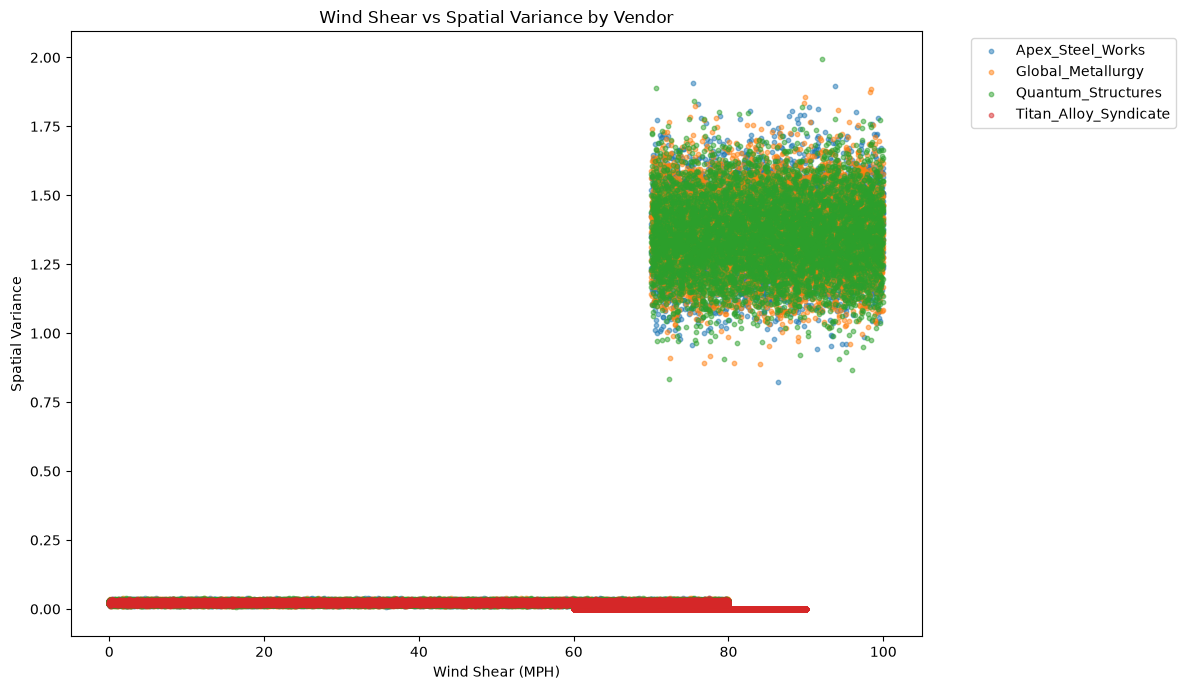

In [67]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))
for vendor, vendor_data in plot_df.groupby("Vendor"):
    plt.scatter(vendor_data["Wind_Shear_MPH"],vendor_data["Spatial_Variance"],label=vendor,alpha=0.5,s=10)
    
plt.xlabel("Wind Shear (MPH)")
plt.ylabel("Spatial Variance")
plt.title("Wind Shear vs Spatial Variance by Vendor")
plt.legend(bbox_to_anchor=(1.05, 1),loc="upper left")
plt.tight_layout()
plt.show()

### Identify the impossible cluster
- High Wind + near-zero Spatial Variance

In [68]:
print(plot_df["Spatial_Variance"].describe())
print(plot_df["Wind_Shear_MPH"].describe())

count    1.000000e+06
mean     4.583500e-02
std      1.789351e-01
min      3.881437e-07
25%      2.019022e-02
50%      2.264144e-02
75%      2.513698e-02
max      1.994869e+00
Name: Spatial_Variance, dtype: float64
count    1000000.000000
mean          42.560879
std           24.349606
min            0.000145
25%           21.481064
50%           42.885542
75%           63.833715
max           99.998695
Name: Wind_Shear_MPH, dtype: float64


- Then identify potentially flat/high-wind observations. For example, use a very small variance threshold

In [69]:
variance_threshold = 1e-6
high_wind_threshold = plot_df["Wind_Shear_MPH"].quantile(0.90)
impossible_cluster = plot_df[(plot_df["Spatial_Variance"] <= variance_threshold) & (plot_df["Wind_Shear_MPH"] >= high_wind_threshold)]
print("High-wind / near-zero-variance samples:",len(impossible_cluster))
print(impossible_cluster.head())

High-wind / near-zero-variance samples: 9967
     Wind_Shear_MPH  Spatial_Variance                 Vendor
9         80.387445      9.208828e-07  Titan_Alloy_Syndicate
284       78.609457      9.411514e-07  Titan_Alloy_Syndicate
393       79.141055      8.571681e-07  Titan_Alloy_Syndicate
572       75.634993      9.755802e-07  Titan_Alloy_Syndicate
649       76.069731      8.584129e-07  Titan_Alloy_Syndicate


### 2D Sobel spatial gradient

In [70]:
def calculate_sobel_gradient(matrix_tensor):
    """
    Calculate 2D Sobel gradient magnitude
    for an 8x8 strain matrix.

    Returns:
        gradient_magnitude: 8x8 tensor
    """

    if not isinstance(matrix_tensor, torch.Tensor):
        return None

    matrix = matrix_tensor.squeeze(0)

    if matrix.shape != (8, 8):
        return None

    sobel_x = torch.tensor([[-1, 0, 1],
                            [-2, 0, 2],
                            [-1, 0, 1]],dtype=torch.float32)

    sobel_y = torch.tensor([[-1, -2, -1],
                            [0, 0, 0],
                            [1, 2, 1]],dtype=torch.float32)

    matrix = matrix.unsqueeze(0).unsqueeze(0)
    sobel_x = sobel_x.unsqueeze(0).unsqueeze(0)
    sobel_y = sobel_y.unsqueeze(0).unsqueeze(0)
    gradient_x = torch.nn.functional.conv2d(matrix,sobel_x,padding=1)
    gradient_y = torch.nn.functional.conv2d(matrix,sobel_y,padding=1)
    gradient_magnitude = torch.sqrt(gradient_x ** 2 + gradient_y ** 2)

    return gradient_magnitude.squeeze(0).squeeze(0)

In [71]:
matrix_tensor = processed_chunks[0]["Strain_Tensor"].iloc[0]
gradient = calculate_sobel_gradient(matrix_tensor)
print("Gradient shape:", gradient.shape)
print("Gradient dtype:", gradient.dtype)

Gradient shape: torch.Size([8, 8])
Gradient dtype: torch.float32


### Mean gradient magnitude: legitimate vs spoofed

In [73]:
def mean_gradient_magnitude(matrix_tensor):
    gradient = calculate_sobel_gradient( matrix_tensor)
    if gradient is None:
        return np.nan

    return float( gradient.mean().item())

In [74]:
for chunk_number, chunk in enumerate(processed_chunks,start=1):
    chunk["Mean_Gradient_Magnitude"] = (chunk["Strain_Tensor"].apply(mean_gradient_magnitude).astype(np.float32))
    print(f"Chunk {chunk_number}: "
          f"Gradient magnitude calculated")

Chunk 1: Gradient magnitude calculated
Chunk 2: Gradient magnitude calculated
Chunk 3: Gradient magnitude calculated
Chunk 4: Gradient magnitude calculated
Chunk 5: Gradient magnitude calculated
Chunk 6: Gradient magnitude calculated
Chunk 7: Gradient magnitude calculated
Chunk 8: Gradient magnitude calculated
Chunk 9: Gradient magnitude calculated
Chunk 10: Gradient magnitude calculated
Chunk 11: Gradient magnitude calculated
Chunk 12: Gradient magnitude calculated
Chunk 13: Gradient magnitude calculated
Chunk 14: Gradient magnitude calculated
Chunk 15: Gradient magnitude calculated
Chunk 16: Gradient magnitude calculated
Chunk 17: Gradient magnitude calculated
Chunk 18: Gradient magnitude calculated
Chunk 19: Gradient magnitude calculated
Chunk 20: Gradient magnitude calculated


In [75]:
gradient_records = []

for chunk in processed_chunks:
    gradient_records.append(
        chunk[[ TARGET_COLUMN,
                "Mean_Gradient_Magnitude"
            ]])

gradient_df = pd.concat(gradient_records,ignore_index=True)
gradient_summary = (gradient_df.groupby(TARGET_COLUMN)["Mean_Gradient_Magnitude"].agg(["count", "mean", "median", "std"]))
print(gradient_summary)

                          count      mean    median       std
MicroFracture_Triggered                                      
0                        932024  2.399191  2.398086  0.048326
1                         67976  2.930748  1.856184  1.807870


### Identify near-zero gradient matrices

In [76]:
GRADIENT_THRESHOLD = 1e-6
flat_matrix_records = []
global_index = 0

for chunk_number, chunk in enumerate(processed_chunks):
    for local_index in range(len(chunk)):
        gradient_value = chunk["Mean_Gradient_Magnitude"].iloc[local_index]

        if gradient_value <= GRADIENT_THRESHOLD:
            flat_matrix_records.append({"global_index": global_index,
                                        "chunk_number": chunk_number,
                                        "local_index": local_index,
                                        "Vendor": chunk["Vendor"].iloc[local_index],
                                        "Wind_Shear_MPH": chunk[
                                        "Wind_Shear_MPH"].iloc[local_index],
                                        "Spatial_Variance": chunk[
                                        "Spatial_Variance"].iloc[local_index],
                                        "Mean_Gradient_Magnitude": gradient_value,
                                        "Target": chunk[TARGET_COLUMN].iloc[local_index]})

        global_index += 1

flat_matrix_df = pd.DataFrame(flat_matrix_records)
print("Near-zero gradient matrices:",len(flat_matrix_df))
print(flat_matrix_df.head())

Near-zero gradient matrices: 0
Empty DataFrame
Columns: []
Index: []


- we use GRADIENT_THRESHOLD = 1e-6 But the Sobel operation amplifies small spatial differences. Therefore, a matrix can have very low spatial variance while its Sobel mean gradient is still considerably larger than 1e-6.
    
- We should therefore inspect the gradient distribution before choosing the threshold.

In [81]:
gradient_values = pd.concat([chunk["Mean_Gradient_Magnitude"] for chunk in processed_chunks],ignore_index=True)
print(gradient_values.describe())

count    1000000.000000
mean           2.435324
std            0.492186
min            1.854102
25%            2.360741
50%            2.396035
75%            2.431341
max            7.129364
Name: Mean_Gradient_Magnitude, dtype: float64


- No matrices have a near-zero mean Sobel gradient magnitude. The minimum observed mean gradient magnitude is 1.8541. Therefore, the dataset does not contain perfectly flat matrices under the current Sobel-gradient definition.

##### But there is an important distinction
- Your spatial variance does approach zero:
- Minimum ```Spatial Variance = 3.881437e-07``` and you found:``` 9,967 high-wind / near-zero-variance samples```
- So the data clearly contains nearly uniform matrices.

- Recommendation : Use replicate padding instead of zero padding:

### Save Train/Val/Test tensors with torch.save()

- Before Saving need to Scale the Validation and Test because we have scaled the train already;

In [82]:
# Validation
val_tabular_features = []

for idx in val_indices:
    row = metadata_df.iloc[idx]
    chunk_number = int(row["chunk_number"])
    local_index = int(row["local_index"])
    chunk = processed_chunks[chunk_number]
    values = (chunk[TABULAR_COLUMNS].iloc[local_index].to_numpy(dtype=np.float32) )
    val_tabular_features.append(values)

val_tabular_features = np.asarray(val_tabular_features,dtype=np.float32)


# Test
test_tabular_features = []

for idx in test_indices:

    row = metadata_df.iloc[idx]
    chunk_number = int(row["chunk_number"])
    local_index = int(row["local_index"])
    chunk = processed_chunks[chunk_number]
    values = (chunk[TABULAR_COLUMNS].iloc[local_index].to_numpy(dtype=np.float32))
    test_tabular_features.append(values)

test_tabular_features = np.asarray(test_tabular_features,dtype=np.float32)

In [83]:
val_tabular_scaled = tabular_scaler.transform(val_tabular_features).astype(np.float32)
test_tabular_scaled = tabular_scaler.transform(test_tabular_features).astype(np.float32)

In [84]:
print("Train:", train_tabular_scaled.shape)
print("Val  :", val_tabular_scaled.shape)
print("Test :", test_tabular_scaled.shape)

Train: (700000, 2)
Val  : (150000, 2)
Test : (150000, 2)


In [85]:
### Build tensor datasets using the already-scaled features

In [86]:
def build_tensor_dataset(processed_chunks,metadata_df,indices,scaled_tabular_features):
    """
    Build a tensor dictionary containing:

    strain  -> [N, 1, 8, 8]
    tabular -> [N, 2]
    target  -> [N]
    """

    strain_tensors = []
    tabular_tensors = []
    targets = []

    for position, global_index in enumerate(indices):

        row = metadata_df.iloc[global_index]

        chunk_number = int(row["chunk_number"])
        local_index = int(row["local_index"])

        chunk = processed_chunks[chunk_number]
        # Strain tensor
        
        strain_tensor = chunk["Strain_Tensor"].iloc[local_index]
        strain_tensors.append(strain_tensor.to(dtype=torch.float32))
        
        # Scaled tabular features
        tabular_tensor = torch.tensor(scaled_tabular_features[position],dtype=torch.float32)
        tabular_tensors.append(tabular_tensor)

        # Target
        target = torch.tensor(chunk[TARGET_COLUMN].iloc[local_index], dtype=torch.float32)

        targets.append(target)

    return {
        "strain": torch.stack(strain_tensors),
        "tabular": torch.stack(tabular_tensors),
        "target": torch.stack(targets)
    }

In [87]:
train_data = build_tensor_dataset(
    processed_chunks,
    metadata_df,
    train_indices,
    train_tabular_scaled
)

val_data = build_tensor_dataset(
    processed_chunks,
    metadata_df,
    val_indices,
    val_tabular_scaled
)

test_data = build_tensor_dataset(
    processed_chunks,
    metadata_df,
    test_indices,
    test_tabular_scaled
)

In [88]:
print("Train")
print("Strain :", train_data["strain"].shape)
print("Tabular:", train_data["tabular"].shape)
print("Target :", train_data["target"].shape)

print("\nValidation")
print("Strain :", val_data["strain"].shape)
print("Tabular:", val_data["tabular"].shape)
print("Target :", val_data["target"].shape)

print("\nTest")
print("Strain :", test_data["strain"].shape)
print("Tabular:", test_data["tabular"].shape)
print("Target :", test_data["target"].shape)

Train
Strain : torch.Size([700000, 1, 8, 8])
Tabular: torch.Size([700000, 2])
Target : torch.Size([700000])

Validation
Strain : torch.Size([150000, 1, 8, 8])
Tabular: torch.Size([150000, 2])
Target : torch.Size([150000])

Test
Strain : torch.Size([150000, 1, 8, 8])
Tabular: torch.Size([150000, 2])
Target : torch.Size([150000])


In [89]:
import os

TENSOR_DIR = "processed_tensors"
os.makedirs(TENSOR_DIR, exist_ok=True)
torch.save(train_data,os.path.join(TENSOR_DIR,"train_tensors.pt"))
torch.save(val_data,os.path.join(TENSOR_DIR,"val_tensors.pt"))
torch.save(test_data,os.path.join(TENSOR_DIR,"test_tensors.pt"))

print("Train, validation, and test tensors saved successfully.")

Train, validation, and test tensors saved successfully.


In [90]:
loaded_train = torch.load("processed_tensors/train_tensors.pt",weights_only=True)
loaded_val = torch.load("processed_tensors/val_tensors.pt",weights_only=True)
loaded_test = torch.load("processed_tensors/test_tensors.pt",weights_only=True)

print("Train:", loaded_train["strain"].shape)
print("Val  :", loaded_val["strain"].shape)
print("Test :", loaded_test["strain"].shape)

Train: torch.Size([700000, 1, 8, 8])
Val  : torch.Size([150000, 1, 8, 8])
Test : torch.Size([150000, 1, 8, 8])


### Free CPU RAM

In [91]:
del df
del processed_chunks
del metadata_df
del train_indices
del val_indices
del test_indices

del train_tabular_features
del val_tabular_features
del test_tabular_features

del train_tabular_scaled
del val_tabular_scaled
del test_tabular_scaled

del train_dataset
del val_dataset
del test_dataset

del plot_df
del gradient_df

### Force Python garbage collection

In [92]:
import gc
gc.collect()
print("Python garbage collection completed.")

Python garbage collection completed.


### Set strict random seeds

In [93]:
import random
import numpy as np
import torch

RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(RANDOM_SEED)
    torch.cuda.manual_seed_all(RANDOM_SEED)

print(f"Random seed: {RANDOM_SEED}")

Random seed: 42


- For deterministic CUDA behavior:

### Check CUDA availability

In [94]:
cuda_available = torch.cuda.is_available()
print("CUDA available:", cuda_available)

CUDA available: False


### Set the target device

In [95]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Target device:", device)

Target device: cpu


### Document GPU VRAM capacity

In [ ]:
if torch.cuda.is_available():

    gpu_name = torch.cuda.get_device_name(0)

    total_vram_bytes = (torch.cuda.get_device_properties(0)
        .total_memory
    )

    total_vram_gb = (
        total_vram_bytes / (1024 ** 3)
    )

    print("GPU:", gpu_name)
    print(f"VRAM: {total_vram_gb:.2f} GB")

else:

    print("GPU: Not available")
    print("VRAM: N/A")